# Shampoo, from the paper

`optim/shampoo.py` walked through interactively. Source: **Gupta, Koren & Singer,
*Shampoo: Preconditioned Stochastic Tensor Optimization*, arXiv:1802.09568v2**
(`Literature/Shampoo.pdf`).

Written from the pseudocode, not ported -- optax and jax are not in this venv.

| | |
|---|---|
| Alg. 1 | matrix case: `L += G Gt`, `R += Gt G`, `W -= eta L^(-1/4) G R^(-1/4)` |
| Alg. 2 | order-k tensors: one `H^i` per mode, exponent `-1/(2k)` |
| Alg. 3 | diagonal variant, `O(m+n)` state |
| Sec. 5 | a mode wider than ~1200 falls back to Alg. 3 for that mode alone |

**Status.** The algebra below is verified. The regret bound (Thm. 7) is *not*
tested anywhere, and nothing here touches HadNet or real networks.

In [1]:
import os, sys, time
sys.path.insert(0, os.path.abspath(".."))
import torch
from optim.shampoo import (Shampoo, shampoo_step_matrix,
                           _inverse_pth_root, _mode_gram, _mode_mul)

torch.manual_seed(42)
print("torch     ", torch.__version__)
print("cuda      ", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
print("float64   ", "algebra cells run on CPU for determinism")

torch      2.11.0+cu128
cuda       True NVIDIA GeForce RTX 4050 Laptop GPU
float64    algebra cells run on CPU for determinism


## 1. The general path reproduces Algorithm 1 exactly

Algorithm 2 at `k=2` must equal Algorithm 1. This is the real test of the mode
algebra: `_mode_gram` must give `G Gt` for mode 0 and `Gt G` for mode 1, and
`_mode_mul` with a *symmetric* root must act as a left- and right-multiply
respectively.

In [2]:
m, n, T, lr, eps = 12, 9, 25, 1e-2, 1e-4

# verbatim Alg. 1
W_ref = torch.zeros(m, n, dtype=torch.float64)
L = eps * torch.eye(m, dtype=torch.float64)
R = eps * torch.eye(n, dtype=torch.float64)

# general Alg. 2 path
W_gen = torch.zeros(m, n, dtype=torch.float64, requires_grad=True)
opt = Shampoo([W_gen], lr=lr, eps=eps, diagonal_threshold=None)

grads = [torch.randn(m, n, dtype=torch.float64) for _ in range(T)]
trail = []
for t, Gt in enumerate(grads):
    W_ref = shampoo_step_matrix(W_ref, Gt, L, R, lr, eps)
    W_gen.grad = Gt.clone()
    opt.step()
    trail.append((W_ref - W_gen.detach()).abs().max().item())

print(f"max |Alg2 - Alg1| after {T} steps : {trail[-1]:.3e}")
print(f"worst over all steps             : {max(trail):.3e}")
print(f"float64 eps for scale            : {torch.finfo(torch.float64).eps:.3e}")

max |Alg2 - Alg1| after 25 steps : 3.469e-18
worst over all steps             : 3.469e-18
float64 eps for scale            : 2.220e-16


## 2. The inverse 4th root

`L^(-1/4)` is built by eigendecomposition in float64 regardless of the
parameter dtype. A `1/4` power amplifies relative error in the *small*
eigenvalues -- which is exactly where the step is largest, so this is not a
place to economise.

In [3]:
A = torch.randn(20, 20, dtype=torch.float64)
A = A @ A.T + 0.5 * torch.eye(20, dtype=torch.float64)

Ai4 = _inverse_pth_root(A, 4, 1e-12)
err = (Ai4 @ Ai4 @ Ai4 @ Ai4 @ A - torch.eye(20, dtype=torch.float64)).abs().max()

print(f"cond(A)                  {torch.linalg.cond(A):.3e}")
print(f"max |A^(-1/4)^4 A - I|   {err:.3e}")

lam_A  = torch.linalg.eigvalsh(A)
lam_Ai = torch.linalg.eigvalsh(Ai4)
print(f"\nspectrum of A      {lam_A.min():.4f} .. {lam_A.max():.4f}")
print(f"spectrum of A^-1/4 {lam_Ai.min():.4f} .. {lam_Ai.max():.4f}")
print(f"condition collapses {torch.linalg.cond(A):.1f} -> "
      f"{torch.linalg.cond(A):.1f}^(1/4) = {torch.linalg.cond(A)**0.25:.3f}")

cond(A)                  1.274e+02
max |A^(-1/4)^4 A - I|   7.796e-15

spectrum of A      0.5782 .. 73.6574
spectrum of A^-1/4 0.3413 .. 1.1468
condition collapses 127.4 -> 127.4^(1/4) = 3.360


## 3. Section 5: the per-mode diagonal fallback

The paper's answer to "this mode is too wide to factor" is **diagonal, not
blocks** -- and the choice is made per mode, so the other modes keep full
preconditioning. Their threshold was "around 1200", reported with no apparent
loss.

In [4]:
P = torch.zeros(5, 2000, requires_grad=True)
opt = Shampoo([P], lr=1e-3, diagonal_threshold=1200)
P.grad = torch.randn(5, 2000)
opt.step()

st = opt.state[P]
print(f"is_diag        {st['is_diag']}")
for i, H in enumerate(st["H"]):
    full = P.shape[i] ** 2
    print(f"  mode {i}: n={P.shape[i]:5d}  state={tuple(H.shape)!s:10}"
          f"  {H.numel():>8,} elements  (full would be {full:>11,})")

saved = 2000**2 - 2000
print(f"\nsaved on mode 1: {saved:,} elements "
      f"= {saved * 4 / 1e6:.1f} MB in float32")

is_diag        [False, True]
  mode 0: n=    5  state=(5, 5)            25 elements  (full would be          25)
  mode 1: n= 2000  state=(2000,)        2,000 elements  (full would be   4,000,000)

saved on mode 1: 3,998,000 elements = 16.0 MB in float32


## 4. The finding that matters in practice: the learning rate does not transfer

A Shampoo step has a completely different natural scale from an SGD step.
Sweeping too narrow a range is the easy way to conclude, wrongly, that Shampoo
does not work -- my first sweep topped out at `lr=10` and clipped its optimum.

Problem: `min ||A W B - Y||_F^2 / 2`, whose Hessian in `vec(W)` is exactly
`BBt (x) AtA`. That Kronecker structure is what Shampoo models, so this is its
best case **by construction** -- a sanity check, not a benchmark.

`A` and `B` are drawn from explicitly seeded generators so this notebook stands
alone; `tests/test_shampoo.py` seeds globally and so draws different matrices.
The numbers there differ in the third digit. Both are real; neither is the
canonical one.

In [5]:
mm = nn_ = 40

def illcond(k, cond, seed):
    g = torch.Generator().manual_seed(seed)
    Q, _ = torch.linalg.qr(torch.randn(k, k, dtype=torch.float64, generator=g))
    s = torch.logspace(0, -torch.log10(torch.tensor(float(cond))), k,
                       dtype=torch.float64)
    return (Q * s) @ Q.T

A = illcond(mm, 1e3, 7)
B = illcond(nn_, 1e3, 8)
Wstar = torch.randn(mm, nn_, dtype=torch.float64)
Y = A @ Wstar @ B

print(f"cond(A)        {torch.linalg.cond(A):.2e}")
print(f"cond(B)        {torch.linalg.cond(B):.2e}")
print(f"cond(Hessian)  {torch.linalg.cond(A.T@A) * torch.linalg.cond(B@B.T):.2e}")

def run(ctor, lr, steps=200, trace=False):
    W = torch.zeros(mm, nn_, dtype=torch.float64, requires_grad=True)
    o = ctor([W], lr)
    hist, best = [], float("inf")
    for _ in range(steps):
        o.zero_grad()
        loss = 0.5 * ((A @ W @ B - Y) ** 2).sum()
        loss.backward(); o.step()
        v = loss.item()
        if v != v or v == float("inf"):
            return (float("inf"), hist) if trace else float("inf")
        best = min(best, v); hist.append(v)
    return (best, hist) if trace else best

OPTS = {
    "SGD":     lambda ps, lr: torch.optim.SGD(ps, lr=lr),
    "AdaGrad": lambda ps, lr: torch.optim.Adagrad(ps, lr=lr),
    "Shampoo": lambda ps, lr: Shampoo(ps, lr=lr, eps=1e-6),
}
sweep = [10.0 ** e for e in range(-6, 6)]

t0 = time.time()
curves = {k: [run(c, lr) for lr in sweep] for k, c in OPTS.items()}
best = {k: min(zip(v, sweep)) for k, v in curves.items()}
print(f"\nswept {len(sweep)} lrs x {len(OPTS)} optimisers in {time.time()-t0:.1f}s\n")
for k, (loss, lr) in best.items():
    print(f"  {k:9} best loss {loss:.6e}  at lr={lr:g}")

cond(A)        1.00e+03
cond(B)        1.00e+03
cond(Hessian)  1.00e+12



swept 12 lrs x 3 optimisers in 10.0s

  SGD       best loss 7.807722e-02  at lr=1
  AdaGrad   best loss 3.507314e-02  at lr=0.1
  Shampoo   best loss 2.784725e-06  at lr=10000


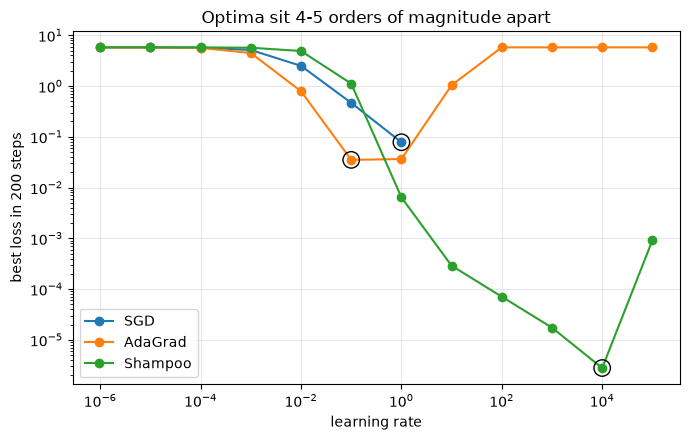

In [6]:
# Loss vs learning rate. Falls back to a printed table with no matplotlib.
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for k, v in curves.items():
        finite = [(l, y) for l, y in zip(sweep, v) if y != float("inf")]
        ax.plot([p[0] for p in finite], [p[1] for p in finite],
                marker="o", label=k)
    for k, (loss, lr) in best.items():
        ax.scatter([lr], [loss], s=140, facecolors="none",
                   edgecolors="black", zorder=5)
    ax.set(xscale="log", yscale="log", xlabel="learning rate",
           ylabel="best loss in 200 steps",
           title="Optima sit 4-5 orders of magnitude apart")
    ax.legend(); ax.grid(alpha=.3)
    plt.tight_layout(); plt.show()
except ImportError:
    print(f"{'lr':>10}  " + "".join(f"{k:>14}" for k in curves))
    for i, lr in enumerate(sweep):
        row = "".join(
            f"{(curves[k][i] if curves[k][i] != float('inf') else float('nan')):>14.3e}"
            for k in curves)
        print(f"{lr:>10.0e}  {row}")

## 5. Convergence at each optimiser's own best learning rate

Comparing at a *shared* learning rate would only measure which optimiser
happens to like that number. Each gets its own best from the sweep above.

Shampoo start   5.7706e+00
        peak    7.9079e+07  at step 2
        rise    7.1 orders of magnitude above start
        back below start at step 54
        final   2.7847e-06


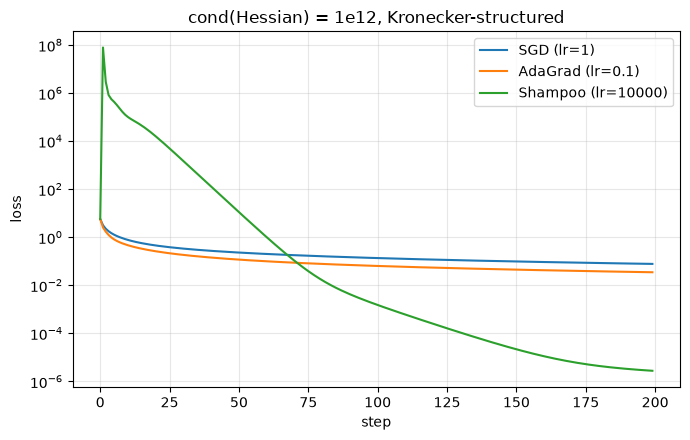

In [7]:
hists = {k: run(OPTS[k], lr, steps=200, trace=True)[1]
         for k, (_, lr) in best.items()}

# The sweep reports min-over-trajectory, which hides what Shampoo does early.
h = hists["Shampoo"]
pk = max(h); pk_at = h.index(pk) + 1
recover = next((j + 1 for j, v in enumerate(h) if j > h.index(pk) and v < h[0]), None)
import math
print(f"Shampoo start   {h[0]:.4e}")
print(f"        peak    {pk:.4e}  at step {pk_at}")
print(f"        rise    {math.log10(pk / h[0]):.1f} orders of magnitude above start")
print(f"        back below start at step {recover}")
print(f"        final   {h[-1]:.4e}")

try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for k, h in hists.items():
        ax.plot(h, label=f"{k} (lr={best[k][1]:g})")
    ax.set(yscale="log", xlabel="step", ylabel="loss",
           title="cond(Hessian) = 1e12, Kronecker-structured")
    ax.legend(); ax.grid(alpha=.3)
    plt.tight_layout(); plt.show()
except ImportError:
    for k, h in hists.items():
        marks = [0, 9, 49, 99, 199]
        print(f"{k:9} " + "  ".join(f"t={i+1}:{h[i]:.2e}"
                                     for i in marks if i < len(h)))

### The large best-lr hides a violent transient

Read the trajectory, not just the minimum. The sweep above reports
`min` over 200 steps, which conceals what Shampoo does at the start: at
`lr=1e4` it climbs **about seven orders of magnitude above its own starting
loss within the first few steps**, and does not get back under that starting
loss until roughly a quarter of the run has gone. The exact figures are
printed by the cell above and plotted as the green spike.

The cause is the initialisation. With `H_0 = eps*I` and `eps=1e-6` the first
step is scaled by `eps^(-1/4) = 31.6`, so an `lr` of `1e4` acts like `3e5`
until the gram matrices accumulate enough to damp it. On a convex quadratic
it recovers and still wins by two orders of magnitude; on a non-convex loss
there would be nothing guaranteeing it comes back at all.

Raising `eps` or warming up trades the transient for a slower start. Alg. 1
carries no warmup, so neither does this implementation.

## What this does not establish

- **The regret bound is untested.** Theorem 7's `O(sqrt(T))` claim is not
  checked anywhere in this notebook or in `tests/test_shampoo.py`.
- **Section 4 is Shampoo's best case by construction.** The Hessian there *is*
  a Kronecker product. A real network's is not.
- **No contact with HadNet.** Nothing here has been pointed at the four factors
  `W1, H1, W2, H2`, so none of it belongs in `RESULTS.md` yet.
- **Order-4 is only smoke-tested** in `tests/test_shampoo.py` (loss
  `2.55e+02 -> 2.09e+02` in 60 steps). That problem has a diagonal, non-Kronecker
  Hessian, so slow progress there is expected and says nothing either way.

Next candidates: KFAC (`Literature/KFAC.pdf` ships code listings, so it is
largely transcription), or pointing this at HadNet's factors against the
current Adam setup.